<a href="https://colab.research.google.com/github/PROPRINCE1/Stellar-Classification-Optimization/blob/main/model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Training, Evaluation and Selection

**Author:** Abdullah Irshad CT-24271

This phase compares classification models for the stellar-object dataset. Model selection, cross-validation and hyperparameter tuning use the training set only. The test set is kept untouched until the final evaluation.

## 1. Define the problem

This is a **multi-class classification** problem. The target variable is `class`, containing `GALAXY`, `STAR` and `QSO`. The input features are the five photometric measurements (`u`, `g`, `r`, `i`, `z`), `redshift`, and the derived colour indices (`u_g`, `g_r`, `r_i`, `i_z`).

The aim is to predict the type of celestial object from its measured features. Machine learning is suitable because these measurements contain patterns that can be learned from labelled examples and then used to classify unseen observations.

**Feature-reduction objective:** The original project also investigates how many input features can be removed while keeping classification performance close to the full-feature model. We will test different feature counts using cross-validation on the training set, then evaluate the selected reduced-feature model on the test set once.

## 2. Load the prepared data

The files below should be the train/test files created in Phase 1. They must contain the same feature columns and the target column `class`.

**Leakage check:** Any imputer, scaler, encoder or other transformation that learns values from data must be fitted using the training split only. If the Phase 1 preprocessing was fitted before splitting the raw data, recreate the split and preprocessing in Phase 1 before relying on these results.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%load_ext cuml.accel

from IPython.display import display
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')

In [4]:
train = pd.read_csv('stellar_train_preprocessed.csv')
test = pd.read_csv('stellar_test_preprocessed.csv')

TARGET = 'class'
FEATURE_COLUMNS = [col for col in train.columns if col != TARGET]

# Keep the same feature order in both datasets.
X_train = train[FEATURE_COLUMNS].copy()
y_train = train[TARGET].copy()
X_test = test[FEATURE_COLUMNS].copy()
y_test = test[TARGET].copy()

assert TARGET in train.columns and TARGET in test.columns
assert list(X_train.columns) == list(X_test.columns)
assert set(y_train.unique()) == set(y_test.unique()), 'Train and test target classes do not match.'
assert X_train.select_dtypes(include=np.number).shape[1] == len(FEATURE_COLUMNS), 'All model features must be numeric.'

print('Training set:', X_train.shape)
print('Test set:', X_test.shape)
print('Features:', FEATURE_COLUMNS)
print('Classes:', sorted(y_train.unique()))
display(train.head())
display(y_train.value_counts().rename('Count').to_frame())

Training set: (80000, 10)
Test set: (20000, 10)
Features: ['u', 'g', 'r', 'i', 'z', 'redshift', 'u_g', 'g_r', 'r_i', 'i_z']
Classes: ['GALAXY', 'QSO', 'STAR']


,u,g,r,i,z,redshift,u_g,g_r,r_i,i_z,class
0,0.807863,-0.264523,-0.036251,0.256713,0.341550,3.823359,2.002103,-0.641276,-1.033711,-0.360961,QSO
1,1.852762,0.657553,0.957976,1.506844,1.058780,-0.790455,2.401621,-0.594218,-1.737323,1.847422,STAR
2,1.304207,0.940979,0.555803,0.314624,0.256087,-0.024080,0.862321,1.204989,0.953189,0.238903,GALAXY
3,-0.102077,0.162619,0.472190,0.689898,0.752229,2.170571,-0.476786,-0.740200,-0.671192,-0.275496,QSO
4,0.015392,0.683426,1.203405,1.451020,1.942622,1.486243,-1.154502,-1.141430,-0.633919,-2.090700,QSO


,Count
class,
GALAXY,47556
STAR,17275
QSO,15169


## 3. Train and compare multiple models

We use **5-fold stratified cross-validation**. Each fold keeps approximately the same class proportions, which is useful for this multi-class dataset.

Models included:

- **Logistic Regression:** linear classifier that models class probabilities.
- **Linear SVM:** finds separating boundaries with a maximum margin.
- **K-Nearest Neighbors:** predicts from the labels of nearby training examples.
- **Gaussian Naive Bayes:** applies Bayes' rule with a Gaussian feature assumption.
- **Decision Tree:** learns a sequence of feature-based decision rules.
- **Extra Trees:** combines randomized decision trees to reduce variance.
- **HistGradientBoosting:** builds trees sequentially, with later trees correcting earlier errors.
- **Random Forest:** averages many decision trees; it can be accurate but may take longer to train.

The data is already preprocessed in Phase 1, so this section does not fit another scaler or imputer. The `fit_time` and `score_time` values below measure the average time per fold, not the total time for the whole experiment.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro'
}

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1500, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Linear SVM': LinearSVC(C=1.0, dual=False, random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, n_jobs=1),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE, min_samples_leaf=2
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=150, random_state=RANDOM_STATE,
        n_jobs=1, class_weight='balanced'
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        random_state=RANDOM_STATE, learning_rate=0.05,
        max_iter=100, max_leaf_nodes=31
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE,
        n_jobs=1, class_weight='balanced'
    )
}

model_results = []
for name, model in models.items():
    start = time.perf_counter()
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    total_time = time.perf_counter() - start

    model_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_macro'].mean(),
        'Recall': scores['test_recall_macro'].mean(),
        'F1-score': scores['test_f1_macro'].mean(),
        'Fit time (s/fold)': scores['fit_time'].mean(),
        'Score time (s/fold)': scores['score_time'].mean(),
        'Total CV time (s)': total_time
    })
    print(f'{name}: completed in {total_time:.2f} seconds')

comparison_df = pd.DataFrame(model_results).sort_values(
    'F1-score', ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

Logistic Regression: completed in 4.58 seconds
[2026-11-14 16:52:10.731] [CUML] [warning] L-BFGS stopped, because the line search failed to advance (step delta = 0.000000)
Linear SVM: completed in 2.89 seconds
K-Nearest Neighbors: completed in 2.26 seconds
Gaussian Naive Bayes: completed in 1.18 seconds
Decision Tree: completed in 11.24 seconds
Extra Trees: completed in 40.07 seconds
HistGradientBoosting: completed in 17.16 seconds
Random Forest: completed in 178.39 seconds


,Model,Accuracy,Precision,Recall,F1-score,Fit time (s/fold),Score time (s/fold),Total CV time (s)
0,Random Forest,0.9791,0.9789,0.9725,0.9756,35.2205,0.4286,178.3908
1,HistGradientBoosting,0.9771,0.9766,0.9705,0.9735,2.8374,0.5653,17.1570
2,Extra Trees,0.9745,0.9735,0.9681,0.9706,7.3204,0.6680,40.0748
3,Decision Tree,0.9680,0.9654,0.9603,0.9628,1.9954,0.2371,11.2380
4,K-Nearest Neighbors,0.9557,0.9525,0.9489,0.9504,0.0982,0.3267,2.2628
5,Logistic Regression,0.9550,0.9507,0.9469,0.9482,0.6234,0.2766,4.5847
6,Linear SVM,0.9356,0.9309,0.9255,0.9281,0.1587,0.3917,2.8939
7,Gaussian Naive Bayes,0.9271,0.9068,0.9375,0.9198,0.0826,0.1388,1.1826


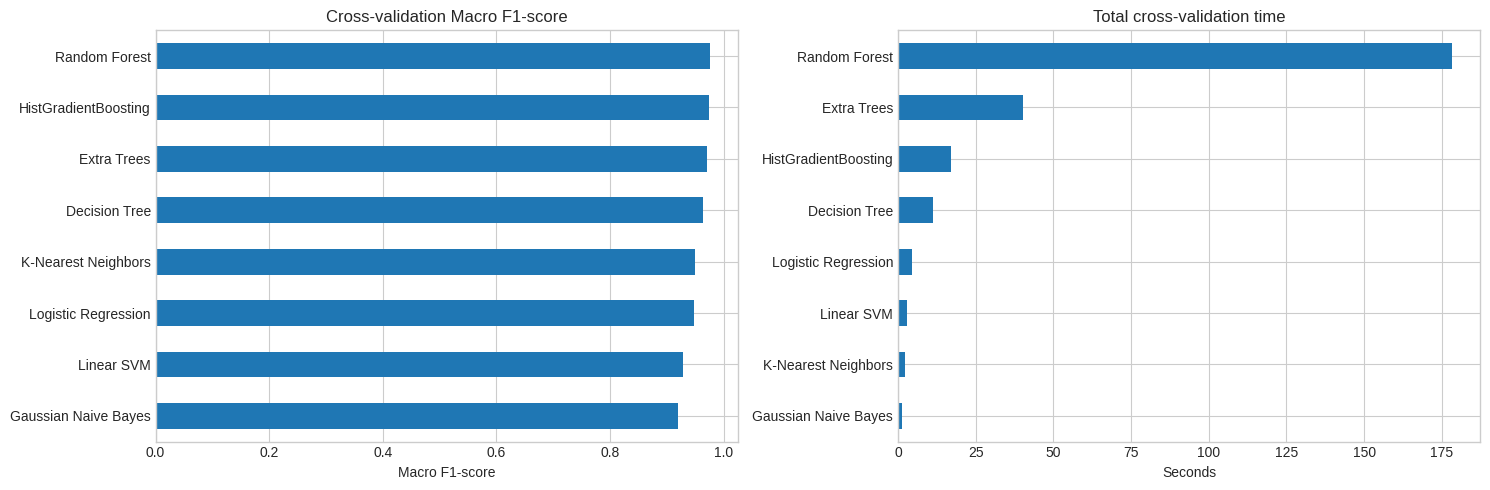

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comparison_df.sort_values('F1-score').plot(
    x='Model', y='F1-score', kind='barh', ax=axes[0], legend=False
)
axes[0].set_title('Cross-validation Macro F1-score')
axes[0].set_xlabel('Macro F1-score')
axes[0].set_ylabel('')

comparison_df.sort_values('Total CV time (s)').plot(
    x='Model', y='Total CV time (s)', kind='barh', ax=axes[1], legend=False
)
axes[1].set_title('Total cross-validation time')
axes[1].set_xlabel('Seconds')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### Model selection

Macro F1-score gives equal importance to each class, rather than allowing the largest class to dominate the score. Training time is also considered because a very small performance gain may not justify a much slower model.

The rule below selects the **fastest model whose macro F1-score is within 0.005 of the best cross-validation F1-score**. This is a practical speed/performance trade-off; it does not automatically select the most accurate model.

In [7]:
best_cv_f1 = comparison_df['F1-score'].max()
acceptable_models = comparison_df[
    comparison_df['F1-score'] >= best_cv_f1 - 0.005
].copy()

selected_model_name = acceptable_models.sort_values(
    'Total CV time (s)'
).iloc[0]['Model']

worst_model_name = comparison_df.iloc[-1]['Model']

print('Highest CV F1-score:', round(best_cv_f1, 4))
print('Selected model (fast and close to best):', selected_model_name)
print('Worst model by macro F1-score:', worst_model_name)
display(acceptable_models[['Model', 'F1-score', 'Total CV time (s)']].round(4))

Highest CV F1-score: 0.9756
Selected model (fast and close to best): HistGradientBoosting
Worst model by macro F1-score: Gaussian Naive Bayes


,Model,F1-score,Total CV time (s)
0,Random Forest,0.9756,178.3908
1,HistGradientBoosting,0.9735,17.1570
2,Extra Trees,0.9706,40.0748


### Baseline model

A `DummyClassifier` predicts the most frequent class. It provides a simple reference point: a useful machine-learning model should perform substantially better than this baseline.

In [8]:
dummy_scores = cross_validate(
    DummyClassifier(strategy='most_frequent'),
    X_train, y_train, cv=cv, scoring=scoring, n_jobs=1
)

dummy_row = {
    'Model': 'Dummy Classifier',
    'Accuracy': dummy_scores['test_accuracy'].mean(),
    'Precision': dummy_scores['test_precision_macro'].mean(),
    'Recall': dummy_scores['test_recall_macro'].mean(),
    'F1-score': dummy_scores['test_f1_macro'].mean(),
    'Fit time (s/fold)': dummy_scores['fit_time'].mean(),
    'Score time (s/fold)': dummy_scores['score_time'].mean()
}
display(pd.DataFrame([dummy_row]).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

,Model,Accuracy,Precision,Recall,F1-score,Fit time (s/fold),Score time (s/fold)
0,Dummy Classifier,0.5944,0.1982,0.3333,0.2485,0.0348,0.1381


## 4. Hyperparameter tuning

Only the selected model is tuned. `GridSearchCV` tests a small parameter grid using the same stratified cross-validation strategy. The test set is not involved.

The parameter grid is kept modest to limit runtime. Different models have different important parameters, so the grid is selected according to the model chosen above.

In [9]:
selected_model = models[selected_model_name]

if selected_model_name == 'HistGradientBoosting':
    param_grid = {
        'learning_rate': [0.05, 0.1],
        'max_iter': [80, 120],
        'max_leaf_nodes': [31, 63],
        'l2_regularization': [0.0, 0.1]
    }
elif selected_model_name == 'Extra Trees':
    param_grid = {
        'n_estimators': [100, 150],
        'max_features': ['sqrt', 0.8],
        'min_samples_leaf': [1, 2]
    }
elif selected_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [80, 120],
        'max_features': ['sqrt', 0.8],
        'min_samples_leaf': [1, 2]
    }
elif selected_model_name == 'Logistic Regression':
    param_grid = {'C': [0.1, 1.0, 3.0]}
elif selected_model_name == 'Linear SVM':
    param_grid = {'C': [0.1, 1.0, 3.0]}
elif selected_model_name == 'K-Nearest Neighbors':
    param_grid = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
elif selected_model_name == 'Decision Tree':
    param_grid = {
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 2, 4]
    }
else:
    param_grid = {'var_smoothing': [1e-9, 1e-8, 1e-7]}

tuning_start = time.perf_counter()
grid_search = GridSearchCV(
    estimator=selected_model,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=1,
    verbose=0
)
grid_search.fit(X_train, y_train)
tuning_time = time.perf_counter() - tuning_start

tuned_model = grid_search.best_estimator_
baseline_cv_f1 = comparison_df.loc[
    comparison_df['Model'] == selected_model_name, 'F1-score'
].iloc[0]

print('Selected model:', selected_model_name)
print('Best parameters:', grid_search.best_params_)
print(f'Before tuning CV F1-score: {baseline_cv_f1:.4f}')
print(f'After tuning CV F1-score:  {grid_search.best_score_:.4f}')
print(f'Tuning time: {tuning_time:.2f} seconds')

Selected model: HistGradientBoosting
Best parameters: {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_iter': 80, 'max_leaf_nodes': 63}
Before tuning CV F1-score: 0.9735
After tuning CV F1-score:  0.9737
Tuning time: 223.31 seconds


,Version,CV Macro F1-score
0,Before tuning,0.9735
1,After tuning,0.9737


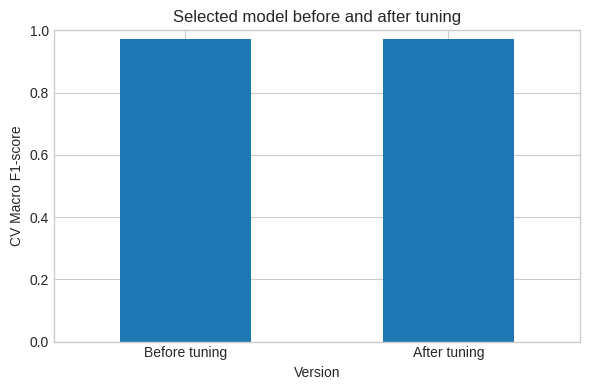

In [10]:
tuning_comparison = pd.DataFrame({
    'Version': ['Before tuning', 'After tuning'],
    'CV Macro F1-score': [baseline_cv_f1, grid_search.best_score_]
})
display(tuning_comparison.round(4))

tuning_comparison.plot(
    x='Version', y='CV Macro F1-score', kind='bar',
    legend=False, figsize=(6, 4), ylim=(0, 1)
)
plt.title('Selected model before and after tuning')
plt.ylabel('CV Macro F1-score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Feature reduction experiment

The project aims to reduce the number of input features while maintaining classification performance. We use `SelectKBest` with the ANOVA F-test (`f_classif`) to rank features.

For each candidate feature count, the selector is placed **inside a pipeline**. Therefore, it is fitted separately on each training fold and does not see that fold's validation data. This avoids feature-selection leakage.

We test several feature counts, including all available features. The final choice is the **smallest feature count within 0.002 macro F1-score of the best result**. This tolerance is defined before looking at test-set results.

In [11]:
feature_counts = sorted(set([2, 4, 6, 8, len(FEATURE_COLUMNS)]))
feature_counts = [k for k in feature_counts if k <= len(FEATURE_COLUMNS)]

feature_results = []
for k in feature_counts:
    feature_pipeline = Pipeline([
        ('selector', SelectKBest(score_func=f_classif, k=k)),
        ('model', grid_search.best_estimator_)
    ])

    start = time.perf_counter()
    scores = cross_validate(
        feature_pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )
    elapsed = time.perf_counter() - start

    feature_results.append({
        'Number of features': k,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_macro'].mean(),
        'Recall': scores['test_recall_macro'].mean(),
        'F1-score': scores['test_f1_macro'].mean(),
        'Total CV time (s)': elapsed
    })
    print(f'{k} features: CV F1 = {scores["test_f1_macro"].mean():.4f}, time = {elapsed:.2f}s')

feature_results_df = pd.DataFrame(feature_results).sort_values(
    'Number of features'
).reset_index(drop=True)
display(feature_results_df.round(4))

best_feature_f1 = feature_results_df['F1-score'].max()
feature_tolerance = 0.002
eligible_feature_counts = feature_results_df[
    feature_results_df['F1-score'] >= best_feature_f1 - feature_tolerance
]
selected_k = int(eligible_feature_counts['Number of features'].min())

print('Best feature-count CV F1-score:', round(best_feature_f1, 4))
print('Selected number of features:', selected_k)

2 features: CV F1 = 0.9567, time = 8.51s
4 features: CV F1 = 0.9700, time = 10.32s
6 features: CV F1 = 0.9732, time = 10.70s
8 features: CV F1 = 0.9733, time = 10.75s
10 features: CV F1 = 0.9737, time = 12.90s


,Number of features,Accuracy,Precision,Recall,F1-score,Total CV time (s)
0,2,0.9624,0.9577,0.9558,0.9567,8.5138
1,4,0.9740,0.9726,0.9674,0.9700,10.3207
2,6,0.9768,0.9762,0.9704,0.9732,10.6975
3,8,0.9769,0.9764,0.9704,0.9733,10.7491
4,10,0.9773,0.9767,0.9709,0.9737,12.9046


Best feature-count CV F1-score: 0.9737
Selected number of features: 6


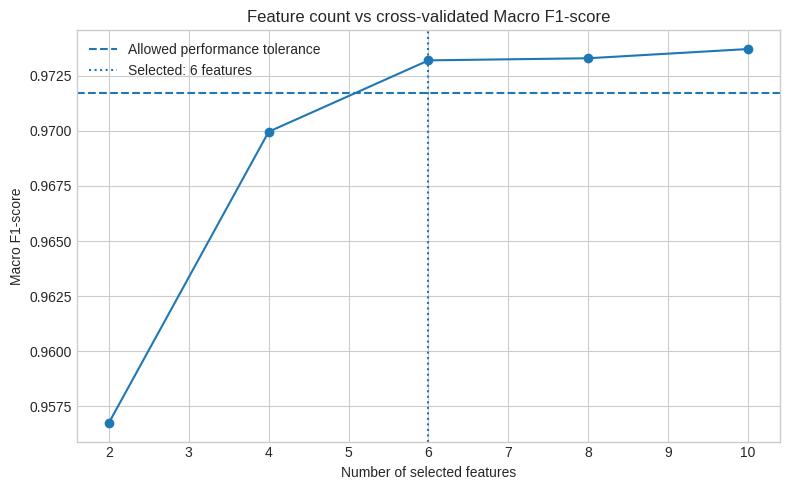

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    feature_results_df['Number of features'],
    feature_results_df['F1-score'],
    marker='o'
)
ax.axhline(best_feature_f1 - feature_tolerance, linestyle='--',
           label='Allowed performance tolerance')
ax.axvline(selected_k, linestyle=':', label=f'Selected: {selected_k} features')
ax.set_title('Feature count vs cross-validated Macro F1-score')
ax.set_xlabel('Number of selected features')
ax.set_ylabel('Macro F1-score')
ax.legend()
plt.tight_layout()
plt.show()

### Selected features

The selector is now fitted once on the complete training set. The selected feature names are reported below. The test set is still not used for this selection.

In [13]:
final_pipeline = Pipeline([
    ('selector', SelectKBest(score_func=f_classif, k=selected_k)),
    ('model', grid_search.best_estimator_)
])

final_pipeline.fit(X_train, y_train)
selected_mask = final_pipeline.named_steps['selector'].get_support()
selected_features = list(X_train.columns[selected_mask])

print('Selected features:', selected_features)
print('Number of selected features:', len(selected_features))
print('Number of removed features:', len(FEATURE_COLUMNS) - len(selected_features))

Selected features: ['i', 'z', 'redshift', 'u_g', 'g_r', 'r_i']
Number of selected features: 6
Number of removed features: 4


## 6. Final evaluation on the untouched test set

At this stage, model selection, cross-validation, tuning and feature-count selection are complete. We now evaluate the final reduced-feature pipeline on the test set for the first time.

For this classification task, accuracy, macro precision, macro recall, macro F1-score and the confusion matrix are appropriate. MAE, MSE, RMSE and R² are regression metrics, so they are not applicable here.

In [14]:
test_predictions = final_pipeline.predict(X_test)

final_accuracy = accuracy_score(y_test, test_predictions)
final_precision = precision_score(y_test, test_predictions, average='macro', zero_division=0)
final_recall = recall_score(y_test, test_predictions, average='macro', zero_division=0)
final_f1 = f1_score(y_test, test_predictions, average='macro', zero_division=0)

final_test_results = pd.DataFrame([{
    'Model': f'{selected_model_name} (tuned, {selected_k} features)',
    'Accuracy': final_accuracy,
    'Precision (macro)': final_precision,
    'Recall (macro)': final_recall,
    'F1-score (macro)': final_f1,
    'Features used': selected_k,
    'Features removed': len(FEATURE_COLUMNS) - selected_k
}])

display(final_test_results.round(4))
print(classification_report(y_test, test_predictions, digits=4, zero_division=0))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Features used,Features removed
0,"HistGradientBoosting (tuned, 6 features)",0.9779,0.9775,0.9716,0.9745,6,4


              precision    recall  f1-score   support

      GALAXY     0.9774    0.9857    0.9815     11889
         QSO     0.9654    0.9341    0.9495      3792
        STAR     0.9899    0.9949    0.9924      4319

    accuracy                         0.9779     20000
   macro avg     0.9775    0.9716    0.9745     20000
weighted avg     0.9778    0.9779    0.9778     20000



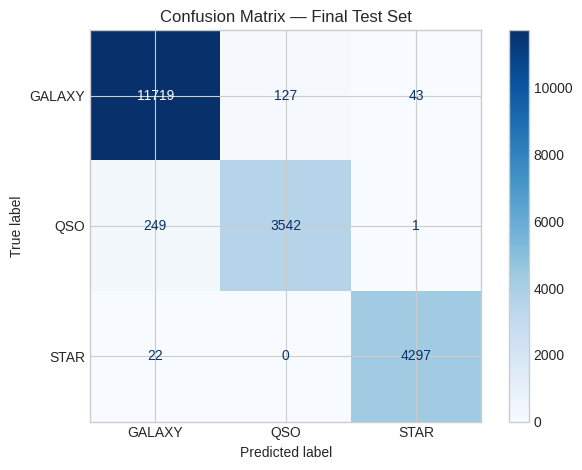

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    labels=sorted(y_train.unique()),
    display_labels=sorted(y_train.unique()),
    cmap='Blues',
    values_format='d'
)
plt.title('Confusion Matrix — Final Test Set')
plt.tight_layout()
plt.show()

## 7. Results and discussion

Use the generated tables and plots to complete the discussion after running the notebook. Report the actual values produced by your run; do not assume that a particular model will always be the best.

Consider the following points:

- **Best and worst models:** Compare macro F1-scores in the cross-validation table. A model with the lowest score may be too simple for the nonlinear patterns in the data, while tree ensembles can model more complex relationships.
- **Training time:** Compare total cross-validation time and average fit time. A small score improvement may not justify a large increase in runtime.
- **Tuning:** Compare the selected model's F1-score before and after tuning. A very small improvement means the original parameters were already reasonable.
- **Feature reduction:** Compare the full-feature score with the score for the selected smaller feature set. The selected feature count is chosen using training folds only.
- **Overfitting/underfitting:** A large gap between training and validation scores can indicate overfitting. A low score on both can indicate underfitting. Cross-validation variation should also be considered.
- **Limitations:** Feature selection based on univariate F-scores may miss useful interactions between features. Results also depend on the quality and representativeness of the dataset and the chosen train/test split.

In [16]:
# Cross-validation train-vs-validation check for the final pipeline.
overfit_check = cross_validate(
    final_pipeline, X_train, y_train,
    cv=cv,
    scoring='f1_macro',
    return_train_score=True,
    n_jobs=1
)

print(f'Mean training-fold F1:   {overfit_check["train_score"].mean():.4f}')
print(f'Mean validation F1:      {overfit_check["test_score"].mean():.4f}')
print(f'Train-validation gap:    {overfit_check["train_score"].mean() - overfit_check["test_score"].mean():.4f}')
print(f'Validation F1 std. dev.: {overfit_check["test_score"].std():.4f}')

Mean training-fold F1:   0.9865
Mean validation F1:      0.9732
Train-validation gap:    0.0133
Validation F1 std. dev.: 0.0007


## 8. Conclusion

The final model is selected using training-only cross-validation, tuned using training-only grid search, and evaluated on the untouched test set. The feature-reduction experiment identifies a smaller feature set that stays within the predefined performance tolerance.

The final conclusion should state the selected algorithm, its test metrics, how many features were retained, how many were removed, whether tuning improved cross-validation performance, and whether the reduction caused a meaningful loss in performance.